In [1]:
import pennylane as qml
from pennylane import math as qml_math
from pennylane import numpy as np
from qiskit.quantum_info import Statevector, DensityMatrix
from qiskit.visualization import array_to_latex
from typing import Callable
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from functools import reduce
from scipy.stats import wasserstein_distance

In [2]:
rng = np.random.default_rng(42)

In [ ]:
# dev = qml.device("default.qubit")
# dev = qml.device("default.mixed")
### Requires adjusting the error threshold in the following file:
### ~/research/quantum-dist-rl/.venv/lib/python3.13/site-packages/pennylane/devices/qubit/sampling.py:530
dev = qml.device("default.qubit", shots=10000)
# dev = qml.device("default.qubit", shots=None)

In [4]:
def is_unitary(m: np.ndarray):
    return np.allclose(np.eye(m.shape[0]), m * m.T.conj())

def is_hermitian(m: np.ndarray):
    return np.allclose(m, m.T.conj())

def is_sorted(x: np.ndarray):
    x = np.array(x)
    return bool(np.all(x[:-1] <= x[1:]))

def softmax(x: np.ndarray):
    y = np.exp(x - np.max(x)) # Stabilize to prevent overflow.
    return y / np.sum(y)

In [5]:
from typing import Any

@qml.qnode(dev)
def circuit(
    wires: list[int],
    funcs: list[Callable[[list[int]], None]] = [],
    func_measure: Callable[[list[int]], Any] = None,
    ):
    if not funcs:
        funcs = [lambda wires: None]
    for func in funcs:
        func(wires)
    if func_measure is not None:
        return func_measure(wires)
    else:
        return qml.state(), qml.probs(wires=wires), qml.density_matrix(wires)

In [6]:
def prepare_action_returns(
    wires: list[int], 
    action_probs_vec: np.ndarray, # shape (n_actions,),
    returns_probs_matrix: np.ndarray, # shape (n_actions, n_returns)
    ):
    # print(f"{action_probs_vec.shape=}")
    # print(f"{returns_probs_matrix.shape=}")
    n_actions = action_probs_vec.shape[0]
    n_returns = returns_probs_matrix.shape[1]
    
    # Get number of qubits needed for actions and returns.
    # (for now) The number of actions and returns must be powers of 2 for this to work properly.
    d_actions = int(np.log2(n_actions))
    # print(f"{d_actions=}")
    if n_actions != 2**d_actions:
        raise ValueError(f"n_actions must be a power of 2, got {n_actions}.")
    d_returns = int(np.log2(n_returns))
    # print(f"{d_returns=}")
    if n_returns != 2**d_returns:
        raise ValueError(f"n_returns must be a power of 2, got {n_returns}.")
    
    # Partition wires into action and return wires.
    # Wire order is: [action wires, return wires]
    if len(wires) != d_actions + d_returns:
        raise ValueError(f"wires must have length {d_actions + d_returns}, got {len(wires)}.")
    wires_action = wires[:d_actions]
    wires_returns = wires[d_actions:]
    # print(f"{wires_action=}, {wires_returns=}")
    
    # Create quantum state based on probability distribution for actions.
    qml.StatePrep(np.sqrt(action_probs_vec), wires=wires_action, normalize=False) # Must normalize since inputs are probability vectors.
    
    # Create operations that prepare return distributions for each action.
    # Every action index must be represented. If no returns are generated
    # for an action, then the operation should be the Identity.
    ops = [
        qml.StatePrep(np.sqrt(returns_probs_matrix[i]), wires=wires_returns, normalize=False) # Must normalize since inputs are probability vectors.
        for i in range(n_actions)
    ]
    qml.Select(ops, control=wires_action)

In [7]:
n_actions = 4 # 4
n_returns = 8 # 8
d_actions = int(np.log2(n_actions))
d_returns = int(np.log2(n_returns))

In [8]:
returns_probs_matrix = np.abs(rng.normal(0, 1, size=(n_actions, n_returns)))
returns_probs_matrix = returns_probs_matrix / np.sum(returns_probs_matrix, axis=1, keepdims=True)  # Normalize to make it a probability vector (sums to 1).

# returns_probs_matrix[[0,3]] = returns_probs_matrix[[3,0]] # Swap some rows.
# returns_probs_matrix[[1,3]] = returns_probs_matrix[[1,3]] # Swap some rows.

In [9]:
# returns_atoms_values_original = np.array([1./n_returns]*n_returns) # DOES NOT WORK!
returns_atoms_values_original = softmax(np.array([float(i)+1 for i in range(n_returns)])/2.) # This works. Monotonically increasing/decreasing probability distribution.
returns_atoms_values_original = returns_atoms_values_original * (n_returns / n_actions)
returns_atoms_values = returns_atoms_values_original.copy()

# returns_atoms_values = returns_atoms_values_original.copy() # DOES NOT WORK. Must at least have square-root term.
# returns_atoms_values = np.sqrt(returns_atoms_values) # This is minimal working representation. Must at least have square-root of probability distribution. Causes L2-norm of diagonal unitary to be 1.
returns_atoms_values = np.sqrt(returns_atoms_values * n_actions) - 0.0196 # values - epsilon.
# returns_atoms_values = np.sqrt(returns_atoms_values*n_actions) # causes a 1:1 match with computing weighted action distribution via expected return.
# returns_atoms_values = np.sqrt(returns_atoms_values*(n_actions*n_returns)/(d_actions*d_returns)*2)
# returns_atoms_values = np.sqrt(returns_atoms_values)*n_actions # causes L2-norm of circuit probs to be close to 1.
# returns_atoms_values = np.sqrt(returns_atoms_values*n_returns/n_actions)
# returns_atoms_values = np.sqrt(returns_atoms_values)*n_actions/n_returns
# returns_atoms_values = np.sqrt(returns_atoms_values)*n_returns/n_actions
# returns_atoms_values = np.sqrt(returns_atoms_values)*n_actions/n_returns
# returns_atoms_values = 1j*np.sqrt(returns_atoms_values)*n_returns/n_actions
# returns_atoms_values = 1j*np.sqrt(returns_atoms_values)
# returns_atoms_values = returns_atoms_values + 1j*np.sqrt(1 - returns_atoms_values**2.) # Convert to complex such that the norm of each element is 1. This will cause the diagonal matrix to be unitary.
# returns_atoms_values = np.sqrt(1 - returns_atoms_values**2.) + 1j*returns_atoms_values # Convert to complex such that the norm of each element is 1. This will cause the diagonal matrix to be unitary.
# returns_atoms_values = np.exp(2*np.pi*1j*returns_atoms_values)
# returns_atoms_values = returns_atoms_values / np.linalg.norm(returns_atoms_values)
# returns_atoms_values = np.exp(1j*returns_atoms_values)

##################
# returns_atoms_values = returns_atoms_values/n_actions
##################

# # Swap real/imaginary parts.
# r = returns_atoms_values.real.copy()
# i = returns_atoms_values.imag.copy()
# returns_atoms_values.real = i
# returns_atoms_values.imag = r

U_returns_atoms = np.diag(returns_atoms_values)

In [10]:
action_probs_vec = [1./n_actions] * n_actions  # Uniform distribution for simplicity
action_probs_vec = np.array(action_probs_vec) # Convert to numpy array for vectorization.

In [11]:
wires = list(range(d_actions + d_returns))
wires_actions = wires[:d_actions]
wires_returns = wires[d_actions:]

funcs = [
    lambda wires: prepare_action_returns(wires, action_probs_vec, returns_probs_matrix), # Prepare the action and return distributions.
    lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=True),
]
func_measure = lambda wires: (
    # qml.state(),
    # qml.probs(wires=wires),
    # qml.density_matrix(wires),
    qml.probs(wires=wires_actions),
    qml.probs(wires=wires_returns),
    )
(
    # state,
    # probs,
    # rho,
    probs_actions,
    probs_returns,
    ) = circuit(wires, funcs=funcs, func_measure=func_measure)

# # replace state and density matrix rho with dummy values.
# state = np.array(list(range(2**len(wires))))
# state = state / np.linalg.norm(state)
# rho = np.identity(len(state))

# print(f"{wires_actions=}")
# print(f"{wires_returns=}")
# print(f"{probs_actions=}")
# print(f"{probs_returns=}")
# print(f"{probs=}")


# # Split the system density matrix into density matrices for the actions and returns subsystems.
# rho_actions = qml_math.partial_trace(rho, indices=wires_returns) # This is the reduced density matrix for actions, trace out the returns.
# rho_returns = qml_math.partial_trace(rho, indices=wires_actions) # This is the reduced density matrix for returns, trace out the actions.

display(array_to_latex(action_probs_vec, prefix="\\textrm{Action probabilities vector:~~}"))
display(array_to_latex(returns_probs_matrix, prefix="\\textrm{Returns probabilities matrix:~~}"))
display(array_to_latex(returns_atoms_values, prefix="\\textrm{Returns atoms values:~~}"))
display(array_to_latex(returns_probs_matrix @ returns_atoms_values_original, prefix="\\textrm{Action expected returns (return dist @ return values):~~}"))
# display(array_to_latex(state, prefix="\\textrm{State:~~}"))
# display(Statevector(state).draw(output='latex', prefix="\\textrm{State:~~}"))
# display(array_to_latex(probs, prefix="\\textrm{Probabilities:~~}"))
# display(DensityMatrix(rho).draw(output='latex', prefix="\\textrm{Rho:~~}"))
# display(array_to_latex(rho_actions, prefix="\\textrm{Rho actions:~~}"))
# display(DensityMatrix(rho_actions).draw(output='latex', prefix="\\textrm{Rho actions:~~}"))
# display(array_to_latex(rho_returns, prefix="\\textrm{Rho returns:~~}"))
# display(DensityMatrix(rho_returns).draw(output='latex', prefix="\\textrm{Rho returns:~~}"))

norm_err=np.float64(0.00010622943305893529)


/Users/derieux/research/quantum-dist-rl/.venv/lib/python3.13/site-packages/pennylane/ops/qubit/matrix_ops.py:170: UserWarning: Operator [[0.29157103 0.         0.         0.         0.         0.
  0.         0.        ]
 [0.         0.37995152 0.         0.         0.         0.
  0.         0.        ]
 [0.         0.         0.4934343  0.         0.         0.
  0.         0.        ]
 [0.         0.         0.         0.63914908 0.         0.
  0.         0.        ]
 [0.         0.         0.         0.         0.82625057 0.
  0.         0.        ]
 [0.         0.         0.         0.         0.         1.06649363
  0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  1.37497182 0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         1.77106566]]
 may not be unitary. Verify unitarity of operation, or use a datatype with increased precision.
  warnings.warn(


<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

In [12]:
# qml.draw_mpl(circuit, wire_order=wires, style='pennylane')(wires, funcs=funcs, func_measure=func_measure)

<>:6: SyntaxWarning: invalid escape sequence '\S'
<>:6: SyntaxWarning: invalid escape sequence '\S'
/var/folders/t7/1jlv9_sn36g96901km63r92m0000gn/T/ipykernel_20681/248471756.py:6: SyntaxWarning: invalid escape sequence '\S'
  plt.title(f"Actions probabilities from input\n($\Sigma = {action_probs_vec.sum():.4f}$)")


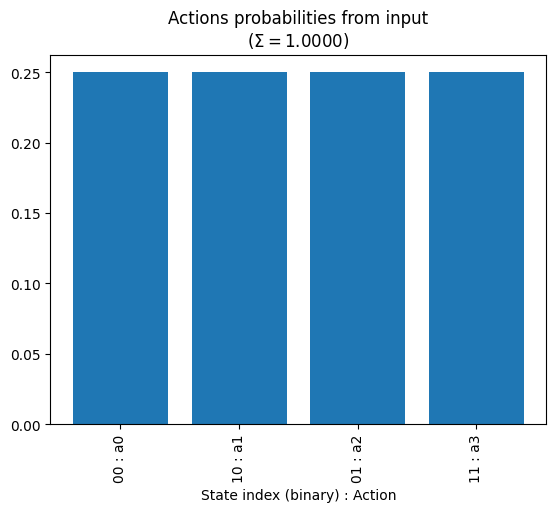

<Figure size 640x480 with 0 Axes>

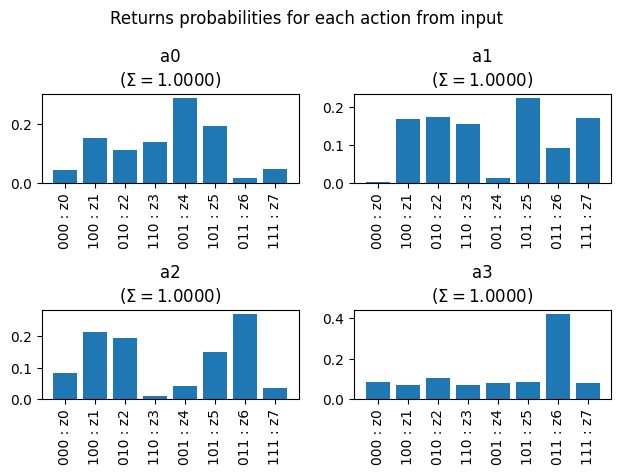

Text(0.5, 0, 'State index (binary) : Action')

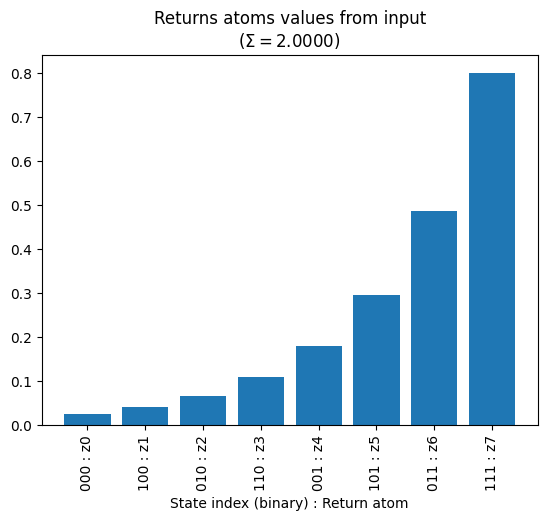

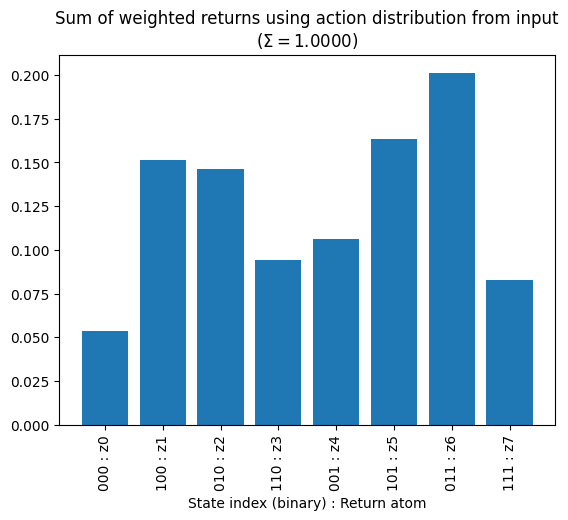

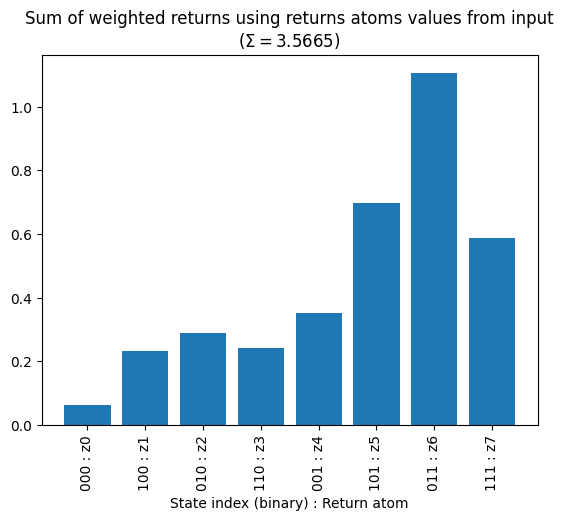

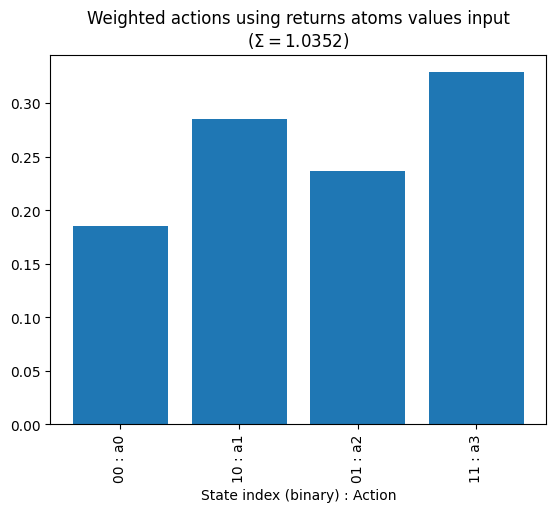

In [13]:
### Plot all inputs for visualization.

plt.figure()
plt.bar(np.arange(n_actions), action_probs_vec)
plt.xticks(np.arange(n_actions), [f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
plt.title(f"Actions probabilities from input\n($\Sigma = {action_probs_vec.sum():.4f}$)")
plt.xlabel("State index (binary) : Action")


plt.figure()
d = int(np.ceil(np.sqrt(n_actions)))
fig, axs = plt.subplots(d, d)
axs = axs.flatten()
for a in range(n_actions):
    axs[a].bar(np.arange(n_returns), returns_probs_matrix[a])
    axs[a].set_xticks(np.arange(n_returns))
    axs[a].set_xticklabels([f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
    axs[a].set_title(f"a{a}\n($\\Sigma = {returns_probs_matrix[a].sum():.4f}$)")
plt.suptitle("Returns probabilities for each action from input")
plt.tight_layout()
plt.show()


plt.figure()
plt.bar(np.arange(n_returns), returns_atoms_values_original)
plt.xticks(np.arange(n_returns), [f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
plt.title(f"Returns atoms values from input\n($\\Sigma = {returns_atoms_values_original.sum():.4f}$)")
plt.xlabel("State index (binary) : Return atom")

#########

plt.figure()
df = pd.DataFrame(returns_probs_matrix, columns=[f"z{i}" for i in range(n_returns)], index=[f"a{i}" for i in range(n_actions)])
weights = pd.Series(action_probs_vec, index=[f"a{i}" for i in range(n_actions)])
weighted_vec = (df.T * weights).sum(axis=1).to_numpy()
plt.bar(np.arange(n_returns), weighted_vec)
plt.xticks(np.arange(n_returns), [f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
plt.title(f"Sum of weighted returns using action distribution from input\n($\\Sigma = {weighted_vec.sum():.4f}$)")
plt.xlabel("State index (binary) : Return atom")


plt.figure()
M = np.einsum('jj,ij->j', U_returns_atoms, returns_probs_matrix)
plt.bar(np.arange(n_returns), np.abs(M))
plt.xticks(np.arange(n_returns), [f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
plt.title(f"Sum of weighted returns using returns atoms values from input\n($\\Sigma = {np.abs(M).sum():.4f}$)")
plt.xlabel("State index (binary) : Return atom")

#########

plt.figure()
plt.bar(np.arange(n_actions), returns_probs_matrix @ returns_atoms_values_original)
plt.xticks(np.arange(n_actions), [f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
plt.title(f"Weighted actions using returns atoms values input\n($\\Sigma = {(returns_probs_matrix @ returns_atoms_values_original).sum():.4f}$)")
plt.xlabel("State index (binary) : Action")

Text(0.5, 0, 'State index (binary) : Action')

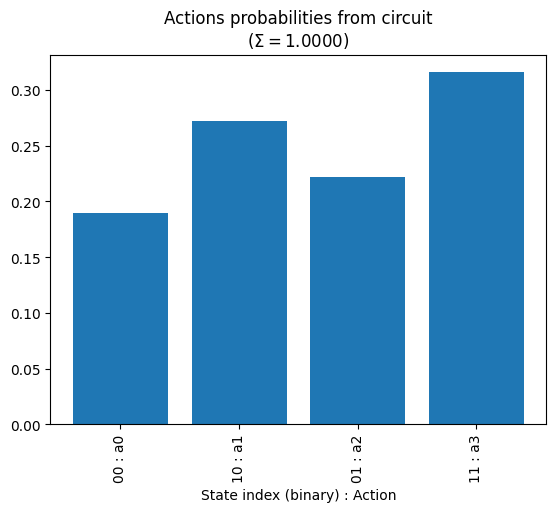

In [14]:
### Probabilities derived from measuring the returns qubits in the circuit.
### NOTE - I've found that the result plotted below will be scaled by a factor of 1/n_actions.

plt.bar(np.arange(n_actions), probs_actions)
plt.xticks(np.arange(n_actions), [f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
plt.title(f"Actions probabilities from circuit\n($\\Sigma = {probs_actions.sum():.4f}$)")
plt.xlabel("State index (binary) : Action")

In [15]:
(returns_probs_matrix @ returns_atoms_values_original).sum() / probs_actions.sum()

tensor(1.03522933, requires_grad=True)

In [16]:
### Rank actions from high-to-low based on their weighted expected return.

# sorted(list(enumerate(returns_probs_matrix @ returns_atoms_values_original)), key=lambda tup: tup[1])[::-1]
action_rank_manual_compute, _ = zip(*sorted(list(enumerate(returns_probs_matrix @ returns_atoms_values_original)), key=lambda tup: tup[1])[::-1])
action_rank_manual_compute

(3, 1, 2, 0)

In [17]:
### Rank actions from high-to-low based on their circuit probability.

action_rank_circuit_probs, _ = zip(*sorted(list(enumerate(probs_actions)), key=lambda tup: tup[1])[::-1])
action_rank_circuit_probs

(3, 1, 2, 0)

In [18]:
### Verify manually computed action rank is the same as the rank estimated by the circuit.

action_rank_manual_compute == action_rank_circuit_probs

True

Text(0.5, 0, 'State index (binary) : Return atom')

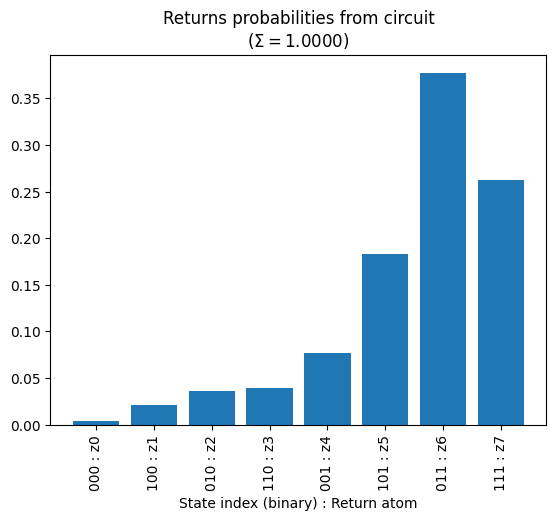

In [19]:
### Probabilities derived from measuring the returns qubits in the circuit.

plt.bar(np.arange(n_returns), probs_returns)
plt.xticks(np.arange(n_returns), [f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
plt.title(f"Returns probabilities from circuit\n($\\Sigma = {probs_returns.sum():.4f}$)")
plt.xlabel("State index (binary) : Return atom")